# EDA 5 — 25개 자치구 종합

1~4단계에서 저장한 구 단위 결과를 한 표(`data/processed/df_gu_eda.csv`, 25행)로 합치고,
**"버스 시설이 필요한 구"를 고를 기준 후보**들을 데이터로 비교한다.

- 수요: 승차합, 하차합, 도착 이동인구(전체/출근/밤/심야), 인구, 업종 종사자합
- 공급: 정류장 수, 노선 수
- 파생: 정류장당 승차, 노선당 승차, 인구 1만명당 정류장, 도착 이동인구 1만명당 정류장,
  버스 이용률(승차÷도착 이동인구), 가중 평균 이동시간, 순유입

가설 검정은 하지 않는다. 정규성(shapiro)·상관은 변수 성격 파악용으로만 본다.

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 250)

GU_ORDER = ["종로구", "중구", "용산구", "성동구", "광진구", "동대문구", "중랑구", "성북구",
            "강북구", "도봉구", "노원구", "은평구", "서대문구", "마포구", "양천구", "강서구",
            "구로구", "금천구", "영등포구", "동작구", "관악구", "서초구", "강남구", "송파구", "강동구"]

## 1. 1~4단계 결과 합치기

In [3]:
bus = pd.read_csv(PROC / "eda1_bus_gu.csv", encoding="utf-8-sig")
mov = pd.read_csv(PROC / "eda2_moving_gu.csv", encoding="utf-8-sig")
ppl = pd.read_csv(PROC / "eda3_people_gu.csv", encoding="utf-8-sig")
biz = pd.read_csv(PROC / "eda4_business_gu.csv", encoding="utf-8-sig")

df = (pd.DataFrame({"자치구": GU_ORDER})
      .merge(bus[["자치구", "승차합", "하차합", "정류장수", "노선수"]], on="자치구", how="left")
      .merge(mov[["자치구", "도착이동인구", "출발이동인구", "순유입", "구내이동비중(%)",
                  "가중평균이동시간", "출근도착", "퇴근도착", "밤도착", "심야도착"]],
             on="자치구", how="left")
      .merge(ppl[["자치구", "인구", "세대", "세대당인구", "고령자비율(%)", "외국인비율(%)"]],
             on="자치구", how="left")
      .merge(biz[["자치구", "종사자수", "사업체수", "특화업종(LQ최대)"]], on="자치구", how="left"))

assert len(df) == 25, len(df)
assert df.isna().sum().sum() == 0, df.isna().sum()
print(df.shape)
df.head()

(25, 22)


,자치구,승차합,하차합,정류장수,노선수,도착이동인구,출발이동인구,순유입,구내이동비중(%),가중평균이동시간,출근도착,퇴근도착,밤도착,심야도착,인구,세대,세대당인구,고령자비율(%),외국인비율(%),종사자수,사업체수,특화업종(LQ최대)
0,종로구,5468935,5205394,349,106,19809988.63,19862431.70,-52443.07,37.080718,16.596827,3522072.19,3050306.37,1183304.77,424279.03,153684,73766,1.96,18.260847,6.122303,16494,5623,커피전문점
1,중구,3776675,3598932,178,103,20275545.43,20296645.78,-21100.35,35.625628,16.634468,4130749.65,2960149.58,1221579.05,560222.82,131450,63767,1.92,18.822366,7.057436,40018,15593,남녀용 겉옷 및 셔츠 도매업
2,용산구,4189977,4086474,323,67,15247193.24,15148400.31,98792.93,43.791917,16.550388,2131690.61,3099372.97,1513742.32,540110.37,236518,111207,2.00,16.684142,6.066769,11449,4464,기타주점업
3,성동구,2807280,2746738,435,58,18076235.50,18121271.09,-45035.59,46.805402,16.370653,2725449.60,3552119.98,1736606.58,626961.55,291609,134533,2.12,16.081808,2.241357,15868,6157,용달 화물자동차 운송업
4,광진구,2749448,2753411,269,41,18715186.44,18675122.83,40063.61,54.272589,16.006705,2169883.22,4148249.86,2182102.79,767907.45,353110,169483,2.01,14.897341,3.512503,15715,6859,기타주점업


## 2. 파생 지표

In [4]:
df["정류장당승차"] = df["승차합"] / df["정류장수"]
df["노선당승차"] = df["승차합"] / df["노선수"]
df["인구만명당정류장"] = df["정류장수"] / (df["인구"] / 10_000)
df["도착이동인구만명당정류장"] = df["정류장수"] / (df["도착이동인구"] / 10_000)
df["버스이용률"] = df["승차합"] / df["도착이동인구"]          # 이동 1명당 버스 승차
df["출근도착비중(%)"] = df["출근도착"] / df["도착이동인구"] * 100
df["밤도착비중(%)"] = df["밤도착"] / df["도착이동인구"] * 100
df["심야도착비중(%)"] = df["심야도착"] / df["도착이동인구"] * 100

df.to_csv(PROC / "df_gu_eda.csv", index=False, encoding="utf-8-sig")
print("저장:", (PROC / "df_gu_eda.csv").resolve(), df.shape)
print("컬럼:", list(df.columns))
df

저장: C:\study\aix\aix_2\data\processed\df_gu_eda.csv (25, 30)
컬럼: ['자치구', '승차합', '하차합', '정류장수', '노선수', '도착이동인구', '출발이동인구', '순유입', '구내이동비중(%)', '가중평균이동시간', '출근도착', '퇴근도착', '밤도착', '심야도착', '인구', '세대', '세대당인구', '고령자비율(%)', '외국인비율(%)', '종사자수', '사업체수', '특화업종(LQ최대)', '정류장당승차', '노선당승차', '인구만명당정류장', '도착이동인구만명당정류장', '버스이용률', '출근도착비중(%)', '밤도착비중(%)', '심야도착비중(%)']


,자치구,승차합,하차합,정류장수,노선수,도착이동인구,출발이동인구,순유입,구내이동비중(%),가중평균이동시간,출근도착,퇴근도착,밤도착,심야도착,인구,세대,세대당인구,고령자비율(%),외국인비율(%),종사자수,사업체수,특화업종(LQ최대),정류장당승차,노선당승차,인구만명당정류장,도착이동인구만명당정류장,버스이용률,출근도착비중(%),밤도착비중(%),심야도착비중(%)
0,종로구,5468935,5205394,349,106,19809988.63,19862431.70,-52443.07,37.080718,16.596827,3522072.19,3050306.37,1183304.77,424279.03,153684,73766,1.96,18.260847,6.122303,16494,5623,커피전문점,15670.300860,51593.726415,22.708935,0.176174,0.276070,17.779274,5.973273,2.141743
1,중구,3776675,3598932,178,103,20275545.43,20296645.78,-21100.35,35.625628,16.634468,4130749.65,2960149.58,1221579.05,560222.82,131450,63767,1.92,18.822366,7.057436,40018,15593,남녀용 겉옷 및 셔츠 도매업,21217.275281,36666.747573,13.541270,0.087790,0.186267,20.373063,6.024889,2.763047
2,용산구,4189977,4086474,323,67,15247193.24,15148400.31,98792.93,43.791917,16.550388,2131690.61,3099372.97,1513742.32,540110.37,236518,111207,2.00,16.684142,6.066769,11449,4464,기타주점업,12972.065015,62536.970149,13.656466,0.211842,0.274803,13.980872,9.928006,3.542359
3,성동구,2807280,2746738,435,58,18076235.50,18121271.09,-45035.59,46.805402,16.370653,2725449.60,3552119.98,1736606.58,626961.55,291609,134533,2.12,16.081808,2.241357,15868,6157,용달 화물자동차 운송업,6453.517241,48401.379310,14.917235,0.240647,0.155302,15.077529,9.607125,3.468430
4,광진구,2749448,2753411,269,41,18715186.44,18675122.83,40063.61,54.272589,16.006705,2169883.22,4148249.86,2182102.79,767907.45,353110,169483,2.01,14.897341,3.512503,15715,6859,기타주점업,10220.996283,67059.707317,7.618023,0.143734,0.146910,11.594238,11.659530,4.103125
5,동대문구,5240565,5115379,306,73,16987577.97,16973103.47,14474.50,47.487632,15.923403,2419653.82,3350508.35,1819566.71,699500.69,352592,169695,1.99,17.857183,4.143599,15237,7614,용달 화물자동차 운송업,17126.029412,71788.561644,8.678586,0.180132,0.308494,14.243666,10.711160,4.117719
6,중랑구,3792541,3740923,380,48,14518503.71,14509927.80,8575.91,56.263815,16.147403,1744082.43,3254976.85,1703681.56,611038.12,393600,187693,2.07,18.508892,1.157774,17700,9723,택시운송업,9980.371053,79011.270833,9.654472,0.261735,0.261221,12.012825,11.734553,4.208685
7,성북구,6236424,6231238,602,99,19524264.96,19558088.65,-33823.69,50.335708,16.086041,2443480.50,4164095.56,2270125.27,767082.61,442680,197296,2.20,17.104681,2.152797,15177,7588,용달 화물자동차 운송업,10359.508306,62994.181818,13.598988,0.308334,0.319419,12.515096,11.627200,3.928868
8,강북구,4825181,4671783,413,67,13079023.71,13084060.28,-5036.57,50.097544,16.218179,1625113.38,2758295.68,1440949.17,508611.41,300824,144725,2.05,21.594354,1.143526,12526,6524,기타주점업,11683.246973,72017.626866,13.728958,0.315773,0.368925,12.425342,11.017253,3.888757
9,도봉구,3304305,3211421,359,46,11243990.02,11253816.27,-9826.25,49.237402,16.038974,1384736.69,2323116.08,1229697.14,422423.27,318100,138836,2.28,20.472179,0.629362,14469,7572,택시운송업,9204.192201,71832.717391,11.285759,0.319282,0.293873,12.315350,10.936484,3.756881


## 3. 주요 변수 25개 구 막대

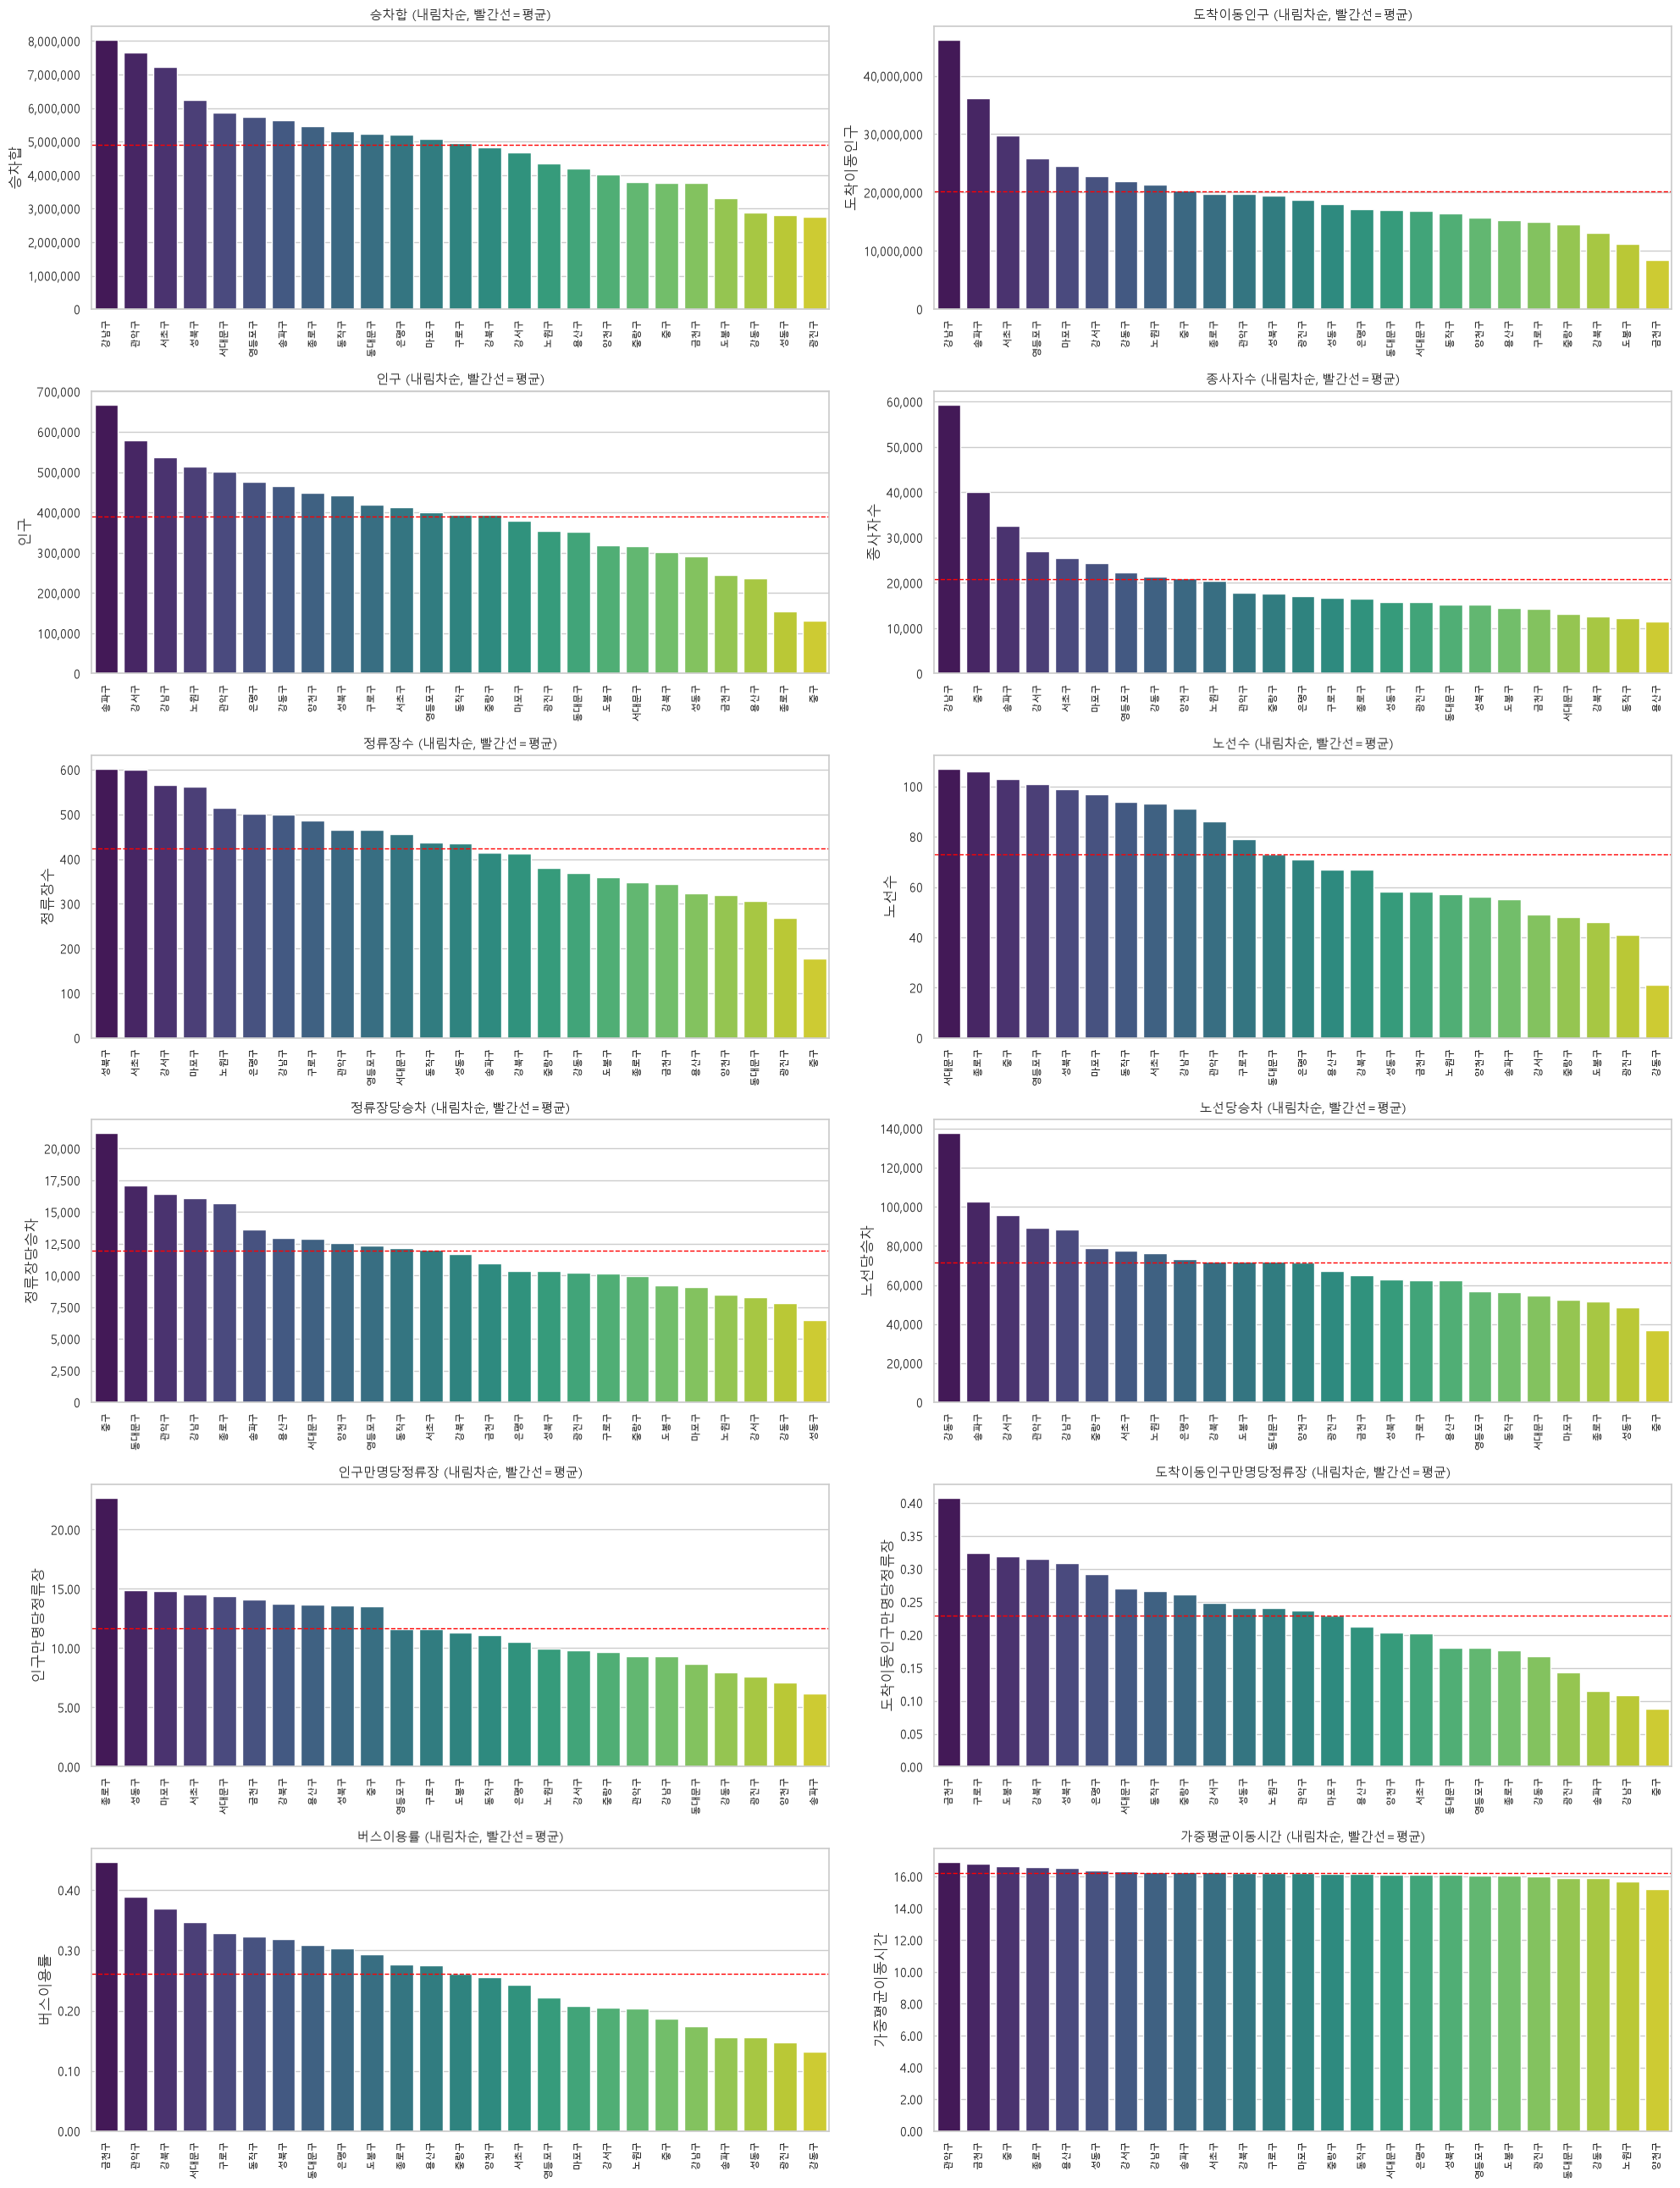

In [5]:
BARS = ["승차합", "도착이동인구", "인구", "종사자수",
        "정류장수", "노선수",
        "정류장당승차", "노선당승차",
        "인구만명당정류장", "도착이동인구만명당정류장",
        "버스이용률", "가중평균이동시간"]

fig, axes = plt.subplots(6, 2, figsize=(20, 26))
for ax, col in zip(axes.ravel(), BARS):
    d = df.sort_values(col, ascending=False)
    sns.barplot(data=d, x="자치구", y=col, hue="자치구", palette="viridis", legend=False, ax=ax)
    ax.axhline(df[col].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"{col} (내림차순, 빨간선=평균)", fontsize=11)
    ax.set_xlabel(""); ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.2f}" if df[col].max() < 100 else "{x:,.0f}"))
plt.tight_layout(); plt.show()

## 4. 수요 vs 공급 산점도 (y = 정류장 수)

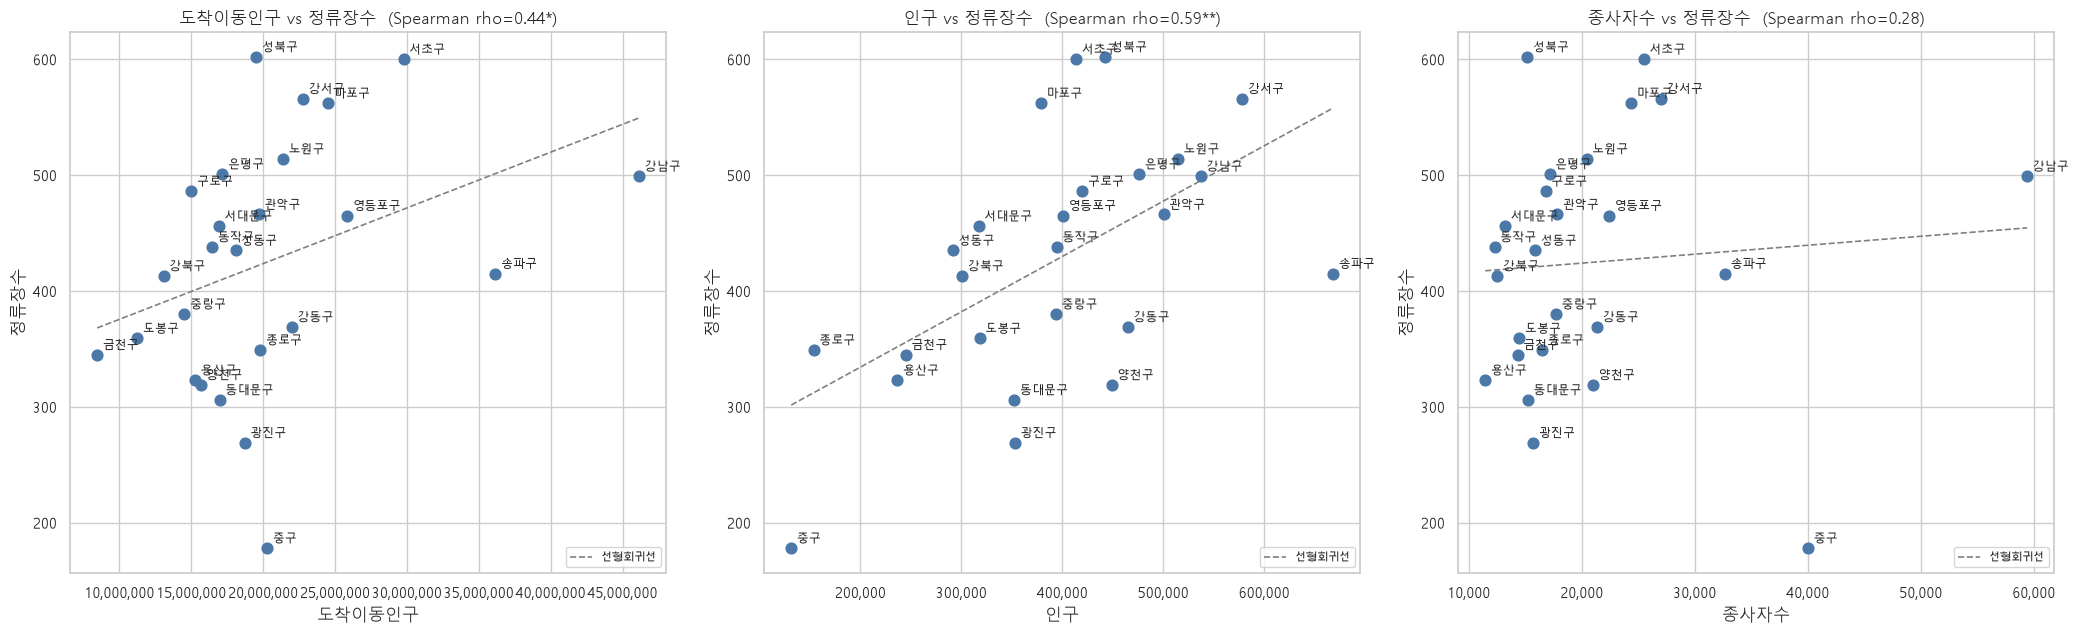

In [6]:
def scatter_gu(ax, xcol, ycol, data=None, highlight=None):
    d = df if data is None else data
    ax.scatter(d[xcol], d[ycol], s=60, color="#4C78A8", zorder=3)
    if highlight is not None:
        h = d[d["자치구"].isin(highlight)]
        ax.scatter(h[xcol], h[ycol], s=130, facecolors="none", edgecolors="#E45756",
                   lw=2.2, zorder=4)
    for _, r in d.iterrows():
        ax.annotate(r["자치구"], (r[xcol], r[ycol]), fontsize=8.5,
                    xytext=(4, 4), textcoords="offset points")
    b, a = np.polyfit(d[xcol], d[ycol], 1)
    xs = np.linspace(d[xcol].min(), d[xcol].max(), 50)
    ax.plot(xs, a + b * xs, "--", color="gray", lw=1.2, zorder=2, label="선형회귀선")
    rho, p = stats.spearmanr(d[xcol], d[ycol])
    star = "**" if p < 0.01 else ("*" if p < 0.05 else "")
    ax.set_title(f"{xcol} vs {ycol}  (Spearman rho={rho:.2f}{star})")
    ax.set_xlabel(xcol); ax.set_ylabel(ycol)
    ax.xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
    ax.legend(loc="lower right", fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, xcol in zip(axes, ["도착이동인구", "인구", "종사자수"]):
    scatter_gu(ax, xcol, "정류장수")
plt.tight_layout(); plt.show()

## 5. 숨은 수요 — 회귀 잔차 (x → 승차합)

x(도착 이동인구 / 인구 / 종사자수)로 승차합을 단순 선형회귀하고,
**회귀선보다 아래(잔차 음수)로 많이 떨어진 구 = 이동(또는 인구·종사자)은 많은데 버스를 덜 타는 구**.
잔차를 표준화(z)해서 비교한다.

In [7]:
XS = ["도착이동인구", "인구", "종사자수"]
resid = pd.DataFrame({"자치구": df["자치구"]})

for x in XS:
    lr = stats.linregress(df[x], df["승차합"])
    pred = lr.intercept + lr.slope * df[x]
    r = df["승차합"] - pred
    resid[f"잔차z_{x}"] = (r - r.mean()) / r.std(ddof=1)
    print(f"[{x} -> 승차합] R^2={lr.rvalue ** 2:.3f}, "
          f"기울기={lr.slope:.4f}, p{'<0.05' if lr.pvalue < 0.05 else '>0.05'}")

resid = resid.set_index("자치구")
resid.round(2)

[도착이동인구 -> 승차합] R^2=0.333, 기울기=0.1035, p<0.05
[인구 -> 승차합] R^2=0.133, 기울기=4.1080, p>0.05
[종사자수 -> 승차합] R^2=0.145, 기울기=51.6735, p>0.05


,잔차z_도착이동인구,잔차z_인구,잔차z_종사자수
자치구,,,
종로구,0.52,1.15,0.59
중구,-0.98,-0.06,-1.62
용산구,-0.18,-0.07,-0.18
성동구,-1.62,-1.29,-1.41
광진구,-1.73,-1.52,-1.44
동대문구,0.57,0.36,0.47
중랑구,-0.46,-0.86,-0.73
성북구,1.20,0.83,1.23
강북구,0.56,0.21,0.26


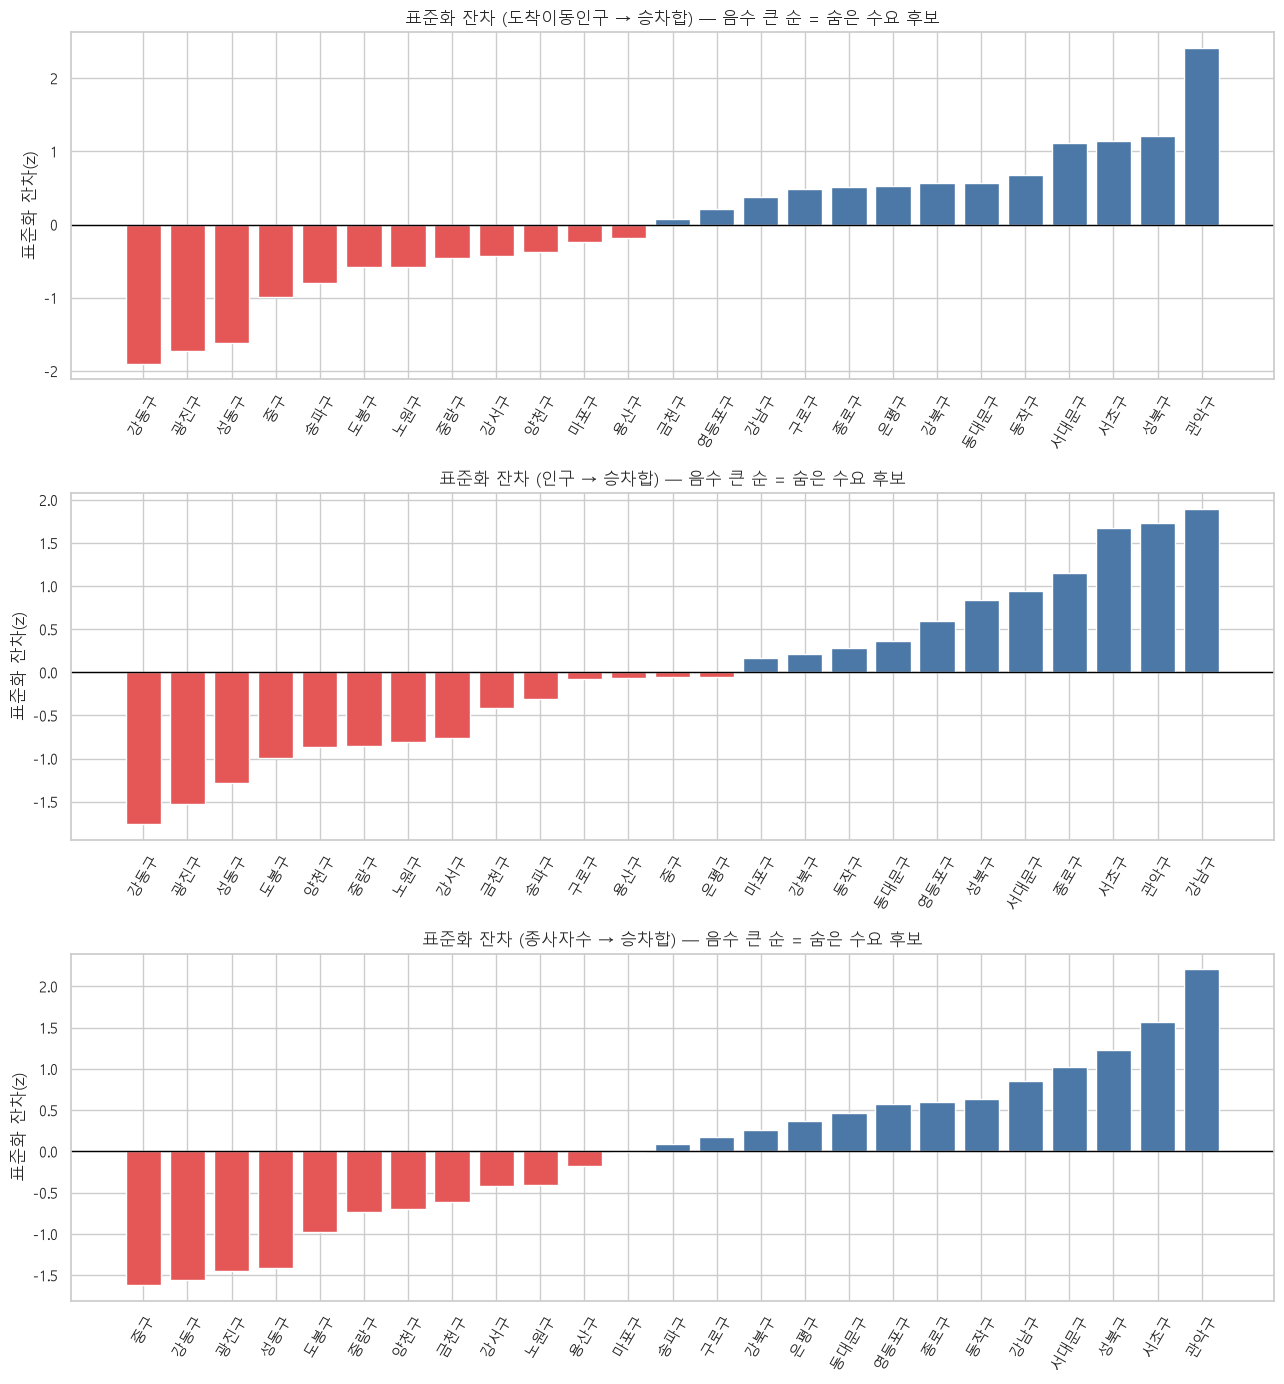

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(13, 14))
for ax, x in zip(axes, XS):
    col = f"잔차z_{x}"
    d = resid[col].sort_values()            # 음수 큰 순
    colors = ["#E45756" if v < 0 else "#4C78A8" for v in d.values]
    ax.bar(d.index, d.values, color=colors)
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"표준화 잔차 ({x} → 승차합) — 음수 큰 순 = 숨은 수요 후보")
    ax.set_ylabel("표준화 잔차(z)")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

잔차 하위 5 (도착이동인구 → 승차합): ['강동구', '광진구', '성동구', '중구', '송파구']
잔차 하위 5 (인구 → 승차합): ['강동구', '광진구', '성동구', '도봉구', '양천구']
잔차 하위 5 (종사자수 → 승차합): ['중구', '강동구', '광진구', '성동구', '도봉구']


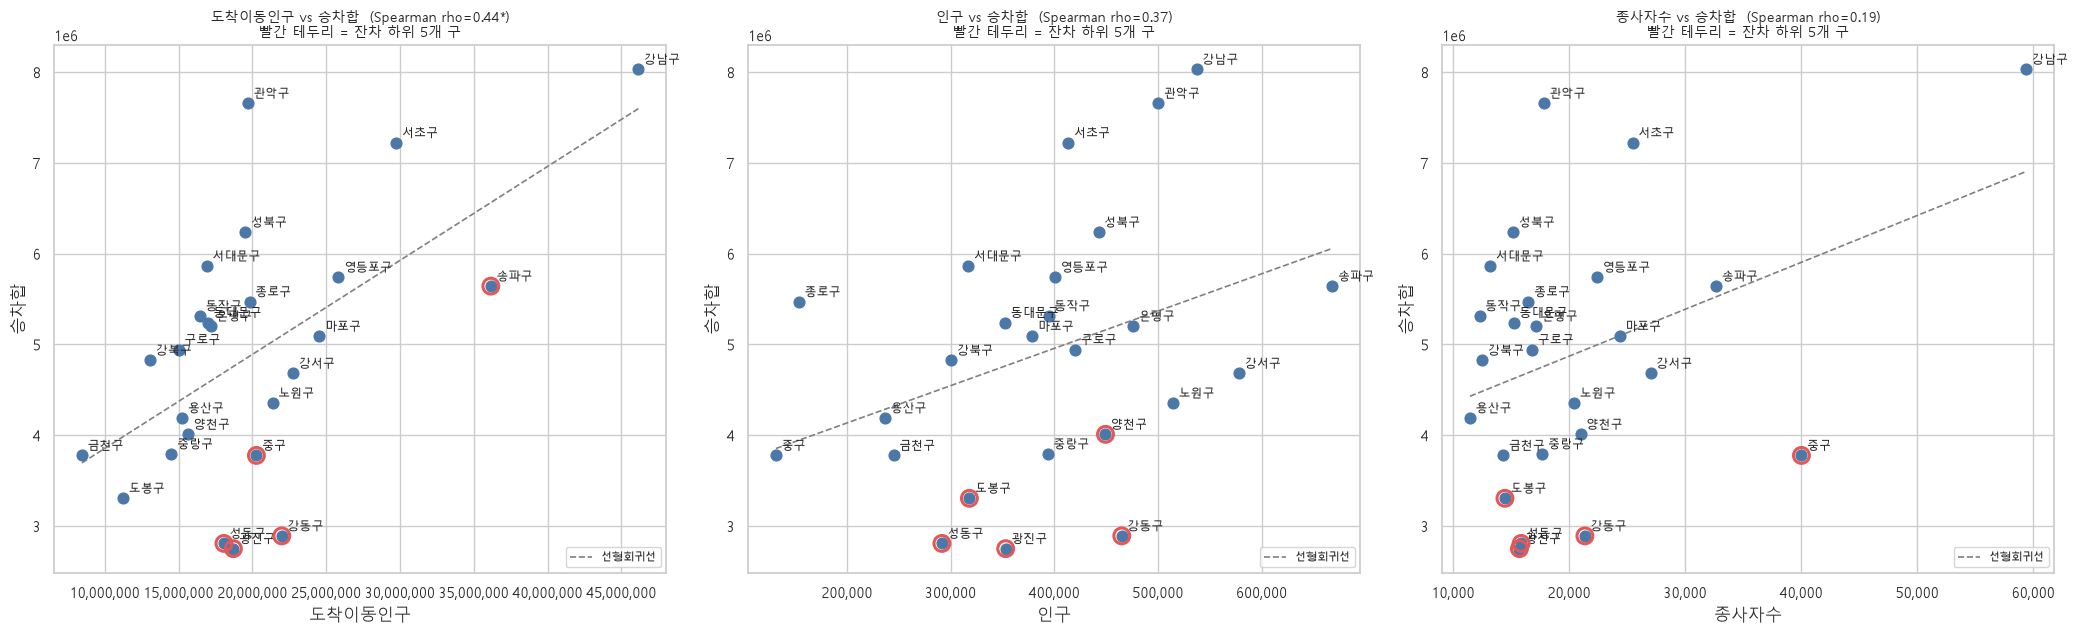

In [9]:
# 산점도에 회귀선 + 구 이름 + 잔차 하위 5개 구 강조
low5 = {x: resid[f"잔차z_{x}"].nsmallest(5).index.tolist() for x in XS}
for x in XS:
    print(f"잔차 하위 5 ({x} → 승차합):", low5[x])

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, x in zip(axes, XS):
    scatter_gu(ax, x, "승차합", highlight=low5[x])
    ax.set_title(ax.get_title() + "\n빨간 테두리 = 잔차 하위 5개 구", fontsize=10)
plt.tight_layout(); plt.show()

In [10]:
# x를 바꿔도 같은 구가 나오는지 (겹치는 구 이름)
ov = pd.DataFrame(index=XS, columns=XS, dtype=object)
for a in XS:
    for b in XS:
        ov.loc[a, b] = ", ".join(sorted(set(low5[a]) & set(low5[b]))) if a != b else "-"
print("세 x 모두에서 잔차 하위 5:", sorted(set(low5[XS[0]]) & set(low5[XS[1]]) & set(low5[XS[2]])))
ov

세 x 모두에서 잔차 하위 5: ['강동구', '광진구', '성동구']


,도착이동인구,인구,종사자수
도착이동인구,-,"강동구, 광진구, 성동구","강동구, 광진구, 성동구, 중구"
인구,"강동구, 광진구, 성동구",-,"강동구, 광진구, 도봉구, 성동구"
종사자수,"강동구, 광진구, 성동구, 중구","강동구, 광진구, 도봉구, 성동구",-


## 6. 변수별 정규성 (shapiro) — p<0.05 / p>0.05 로만

In [11]:
NUMS = ["승차합", "하차합", "정류장수", "노선수", "도착이동인구", "출발이동인구", "순유입",
        "구내이동비중(%)", "가중평균이동시간", "출근도착", "퇴근도착", "밤도착", "심야도착",
        "인구", "세대", "세대당인구", "고령자비율(%)", "외국인비율(%)", "종사자수", "사업체수",
        "정류장당승차", "노선당승차", "인구만명당정류장", "도착이동인구만명당정류장",
        "버스이용률", "출근도착비중(%)", "밤도착비중(%)", "심야도착비중(%)"]

norm = pd.DataFrame({
    "변수": NUMS,
    "shapiro p": ["p<0.05" if stats.shapiro(df[c])[1] < 0.05 else "p>0.05" for c in NUMS],
})
norm["정규성"] = np.where(norm["shapiro p"] == "p<0.05", "정규 아님", "정규 기각 못함")
print("정규 아님(p<0.05):", int((norm["shapiro p"] == "p<0.05").sum()), "/", len(NUMS))
norm

정규 아님(p<0.05): 12 / 28


,변수,shapiro p,정규성
0,승차합,p>0.05,정규 기각 못함
1,하차합,p>0.05,정규 기각 못함
2,정류장수,p>0.05,정규 기각 못함
3,노선수,p>0.05,정규 기각 못함
4,도착이동인구,p<0.05,정규 아님
5,출발이동인구,p<0.05,정규 아님
6,순유입,p<0.05,정규 아님
7,구내이동비중(%),p>0.05,정규 기각 못함
8,가중평균이동시간,p>0.05,정규 기각 못함
9,출근도착,p<0.05,정규 아님


정규 아님인 변수가 많으므로 **상관은 Spearman**으로 본다.

## 7. Spearman 상관 히트맵 (`*p<0.05`, `**p<0.01`)

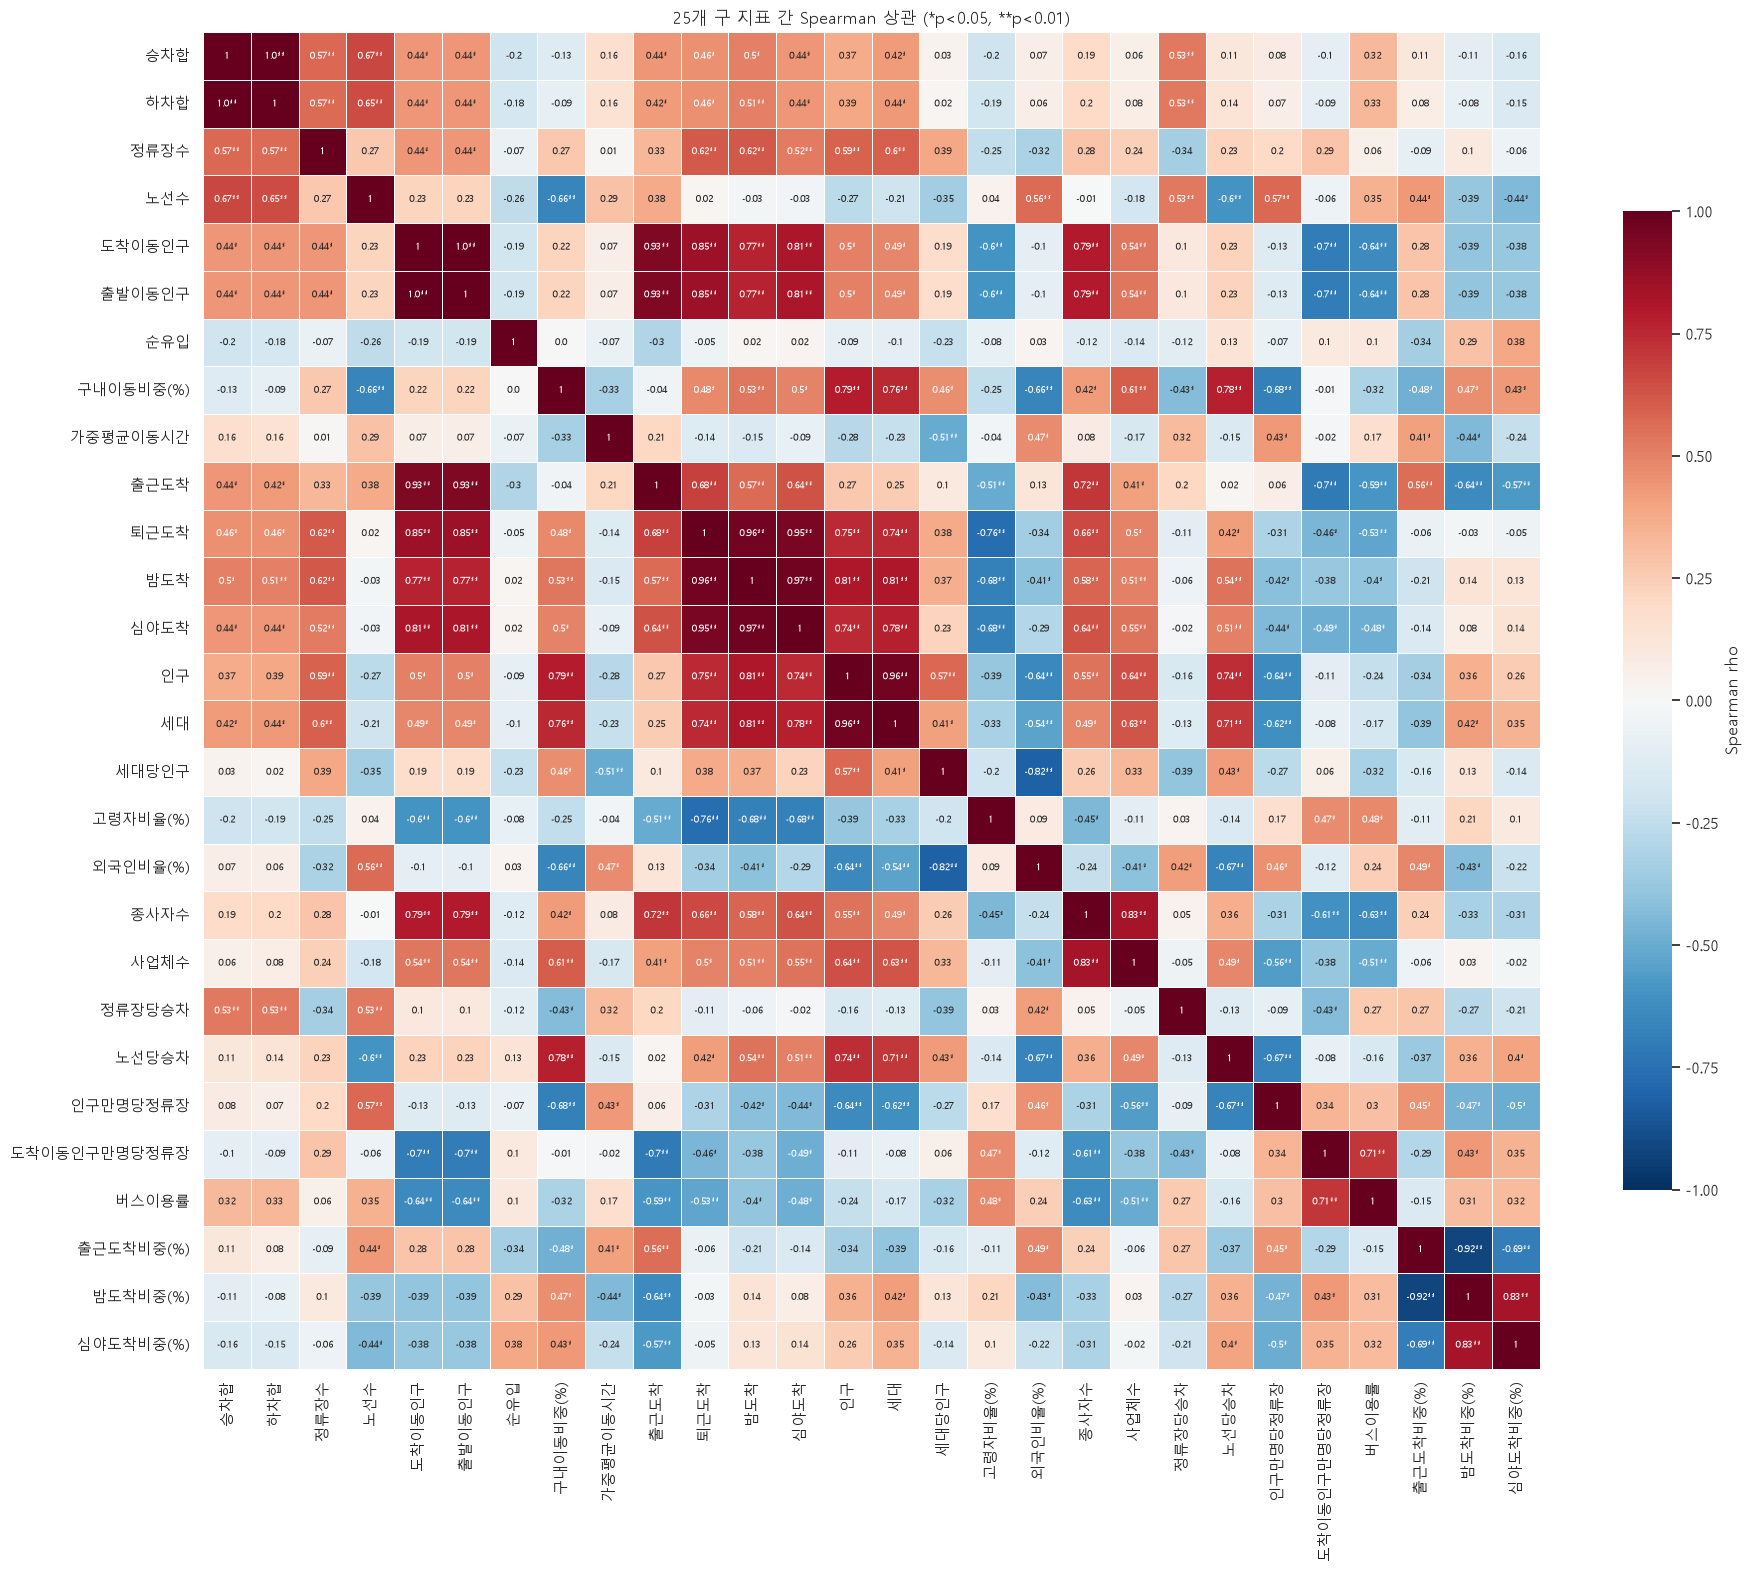

In [12]:
rho = df[NUMS].corr(method="spearman")
pmat = pd.DataFrame(np.ones_like(rho), index=NUMS, columns=NUMS)
for a, b in combinations(NUMS, 2):
    p = stats.spearmanr(df[a], df[b])[1]
    pmat.loc[a, b] = pmat.loc[b, a] = p

ann = rho.round(2).astype(str)
for a in NUMS:
    for b in NUMS:
        if a == b:
            ann.loc[a, b] = "1"
            continue
        p = pmat.loc[a, b]
        ann.loc[a, b] += "**" if p < 0.01 else ("*" if p < 0.05 else "")

fig, ax = plt.subplots(figsize=(19, 16))
sns.heatmap(rho, annot=ann, fmt="", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.4, annot_kws={"size": 6.5},
            cbar_kws={"shrink": .7, "label": "Spearman rho"}, ax=ax)
ax.set_title("25개 구 지표 간 Spearman 상관 (*p<0.05, **p<0.01)")
plt.tight_layout(); plt.show()

In [13]:
# 강한 상관 쌍 (p<0.05 인 것만, |rho| 내림차순)
pairs = []
for a, b in combinations(NUMS, 2):
    p = pmat.loc[a, b]
    if p < 0.05:
        pairs.append({"변수1": a, "변수2": b, "rho": round(rho.loc[a, b], 3),
                      "유의": "**" if p < 0.01 else "*"})
strong = (pd.DataFrame(pairs).assign(절대값=lambda d: d["rho"].abs())
          .sort_values("절대값", ascending=False).drop(columns="절대값")
          .reset_index(drop=True))
strong.index += 1
print("p<0.05 인 쌍:", len(strong), "/ 전체 쌍:", len(NUMS) * (len(NUMS) - 1) // 2)
strong.head(15)

p<0.05 인 쌍: 160 / 전체 쌍: 378


,변수1,변수2,rho,유의
1,도착이동인구,출발이동인구,1.000,**
2,승차합,하차합,0.995,**
3,밤도착,심야도착,0.971,**
4,인구,세대,0.963,**
5,퇴근도착,밤도착,0.962,**
6,퇴근도착,심야도착,0.952,**
7,도착이동인구,출근도착,0.931,**
8,출발이동인구,출근도착,0.931,**
9,출근도착비중(%),밤도착비중(%),-0.916,**
10,출발이동인구,퇴근도착,0.855,**


## 8. 기준 후보별 상위 5 / 하위 5 구

6단계 보고서(`report_EDA.md`)에 그대로 쓸 표. "필요"의 기준은 아직 고르지 않았고,
후보들이 서로 어떤 구를 지목하는지만 비교한다.

In [14]:
CRITERIA = [
    ("수요대비 공급부족: 도착이동인구만명당정류장", "도착이동인구만명당정류장", True),
    ("수요대비 공급부족: 인구만명당정류장", "인구만명당정류장", True),
    ("과밀: 정류장당승차", "정류장당승차", False),
    ("과밀: 노선당승차", "노선당승차", False),
    ("숨은수요: 버스이용률(낮을수록)", "버스이용률", True),
    ("이동시간: 가중평균이동시간(길수록)", "가중평균이동시간", False),
    ("시간대: 출근도착비중(%)", "출근도착비중(%)", False),
    ("시간대: 밤도착비중(%)", "밤도착비중(%)", False),
    ("시간대: 심야도착비중(%)", "심야도착비중(%)", False),
]

rows = []
for label, col, asc in CRITERIA:
    d = df[["자치구", col]].sort_values(col, ascending=asc)
    rows.append({"기준": label,
                 "상위5(필요 큰 쪽)": ", ".join(d.head(5)["자치구"]),
                 "하위5(필요 작은 쪽)": ", ".join(d.tail(5)["자치구"][::-1])})
crit = pd.DataFrame(rows)
crit

,기준,상위5(필요 큰 쪽),하위5(필요 작은 쪽)
0,수요대비 공급부족: 도착이동인구만명당정류장,"중구, 강남구, 송파구, 광진구, 강동구","금천구, 구로구, 도봉구, 강북구, 성북구"
1,수요대비 공급부족: 인구만명당정류장,"송파구, 양천구, 광진구, 강동구, 동대문구","종로구, 성동구, 마포구, 서초구, 서대문구"
2,과밀: 정류장당승차,"중구, 동대문구, 관악구, 강남구, 종로구","성동구, 강동구, 강서구, 노원구, 마포구"
3,과밀: 노선당승차,"강동구, 송파구, 강서구, 관악구, 강남구","중구, 성동구, 종로구, 마포구, 서대문구"
4,숨은수요: 버스이용률(낮을수록),"강동구, 광진구, 성동구, 송파구, 강남구","금천구, 관악구, 강북구, 서대문구, 구로구"
5,이동시간: 가중평균이동시간(길수록),"관악구, 금천구, 중구, 종로구, 용산구","양천구, 노원구, 강동구, 동대문구, 광진구"
6,시간대: 출근도착비중(%),"중구, 금천구, 종로구, 강남구, 서초구","관악구, 은평구, 광진구, 중랑구, 도봉구"
7,시간대: 밤도착비중(%),"관악구, 동작구, 은평구, 중랑구, 광진구","종로구, 중구, 강남구, 서초구, 영등포구"
8,시간대: 심야도착비중(%),"관악구, 동작구, 중랑구, 동대문구, 광진구","종로구, 중구, 서초구, 영등포구, 강남구"


In [15]:
for label, col, asc in CRITERIA:
    d = df[["자치구", col]].sort_values(col, ascending=asc)
    print(f"\n[{label}]  (상위 = 필요 큰 쪽)")
    print(d.head(5).to_string(index=False))
    print("  ... 하위 5 ...")
    print(d.tail(5)[::-1].to_string(index=False))


[수요대비 공급부족: 도착이동인구만명당정류장]  (상위 = 필요 큰 쪽)
자치구  도착이동인구만명당정류장
 중구      0.087790
강남구      0.108120
송파구      0.114778
광진구      0.143734
강동구      0.167755
  ... 하위 5 ...
자치구  도착이동인구만명당정류장
금천구      0.408155
구로구      0.323746
도봉구      0.319282
강북구      0.315773
성북구      0.308334

[수요대비 공급부족: 인구만명당정류장]  (상위 = 필요 큰 쪽)
 자치구  인구만명당정류장
 송파구  6.210148
 양천구  7.098701
 광진구  7.618023
 강동구  7.933829
동대문구  8.678586
  ... 하위 5 ...
 자치구  인구만명당정류장
 종로구 22.708935
 성동구 14.917235
 마포구 14.843026
 서초구 14.504070
서대문구 14.381455

[과밀: 정류장당승차]  (상위 = 필요 큰 쪽)
 자치구       정류장당승차
  중구 21217.275281
동대문구 17126.029412
 관악구 16428.796137
 강남구 16093.152305
 종로구 15670.300860
  ... 하위 5 ...
자치구      정류장당승차
성동구 6453.517241
강동구 7832.121951
강서구 8270.464664
노원구 8469.445525
마포구 9054.201068

[과밀: 노선당승차]  (상위 = 필요 큰 쪽)
자치구         노선당승차
강동구 137621.571429
송파구 102577.127273
강서구  95532.306122
관악구  89021.151163
강남구  88247.065934
  ... 하위 5 ...
 자치구        노선당승차
  중구 36666.747573
 성동구 48401.379310
 종로구 51593.726415
 마포구 52458.360825
서대문구 

In [16]:
# 잔차 기준도 같은 형식으로
for x in XS:
    col = f"잔차z_{x}"
    d = resid[col].sort_values().round(3)
    print(f"\n[숨은수요: 잔차z ({x} → 승차합), 음수 큰 순]")
    print(d.head(5).to_string())
    print("  ... 상위(회귀선 위) 5 ...")
    print(d.tail(5)[::-1].to_string())


[숨은수요: 잔차z (도착이동인구 → 승차합), 음수 큰 순]
자치구
강동구   -1.901
광진구   -1.729
성동구   -1.623
중구    -0.983
송파구   -0.793
  ... 상위(회귀선 위) 5 ...
자치구
관악구     2.410
성북구     1.203
서초구     1.138
서대문구    1.115
동작구     0.682

[숨은수요: 잔차z (인구 → 승차합), 음수 큰 순]
자치구
강동구   -1.763
광진구   -1.522
성동구   -1.287
도봉구   -0.994
양천구   -0.869
  ... 상위(회귀선 위) 5 ...
자치구
강남구     1.897
관악구     1.728
서초구     1.669
종로구     1.152
서대문구    0.943

[숨은수요: 잔차z (종사자수 → 승차합), 음수 큰 순]
자치구
중구    -1.619
강동구   -1.560
광진구   -1.445
성동구   -1.407
도봉구   -0.974
  ... 상위(회귀선 위) 5 ...
자치구
관악구     2.205
서초구     1.573
성북구     1.229
서대문구    1.023
강남구     0.855


## 9. 기준끼리 상위 5개 구가 얼마나 겹치나

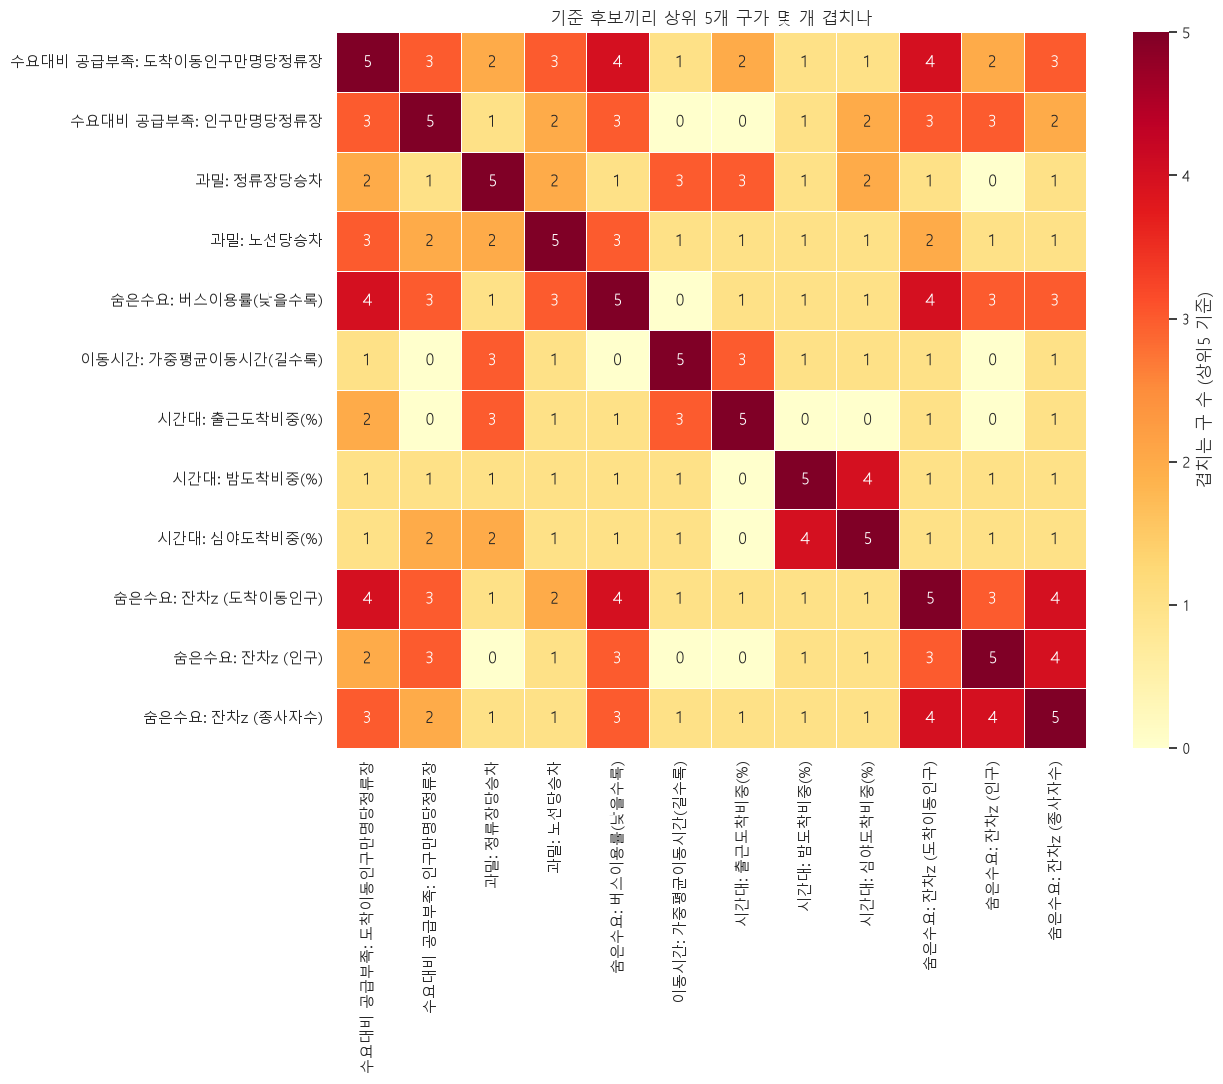

In [17]:
TOP5 = {label: set(df[["자치구", col]].sort_values(col, ascending=asc).head(5)["자치구"])
        for label, col, asc in CRITERIA}
for x in XS:
    TOP5[f"숨은수요: 잔차z ({x})"] = set(resid[f"잔차z_{x}"].nsmallest(5).index)

labels = list(TOP5)
ovm = pd.DataFrame(0, index=labels, columns=labels)
for a, b in combinations(labels, 2):
    ovm.loc[a, b] = ovm.loc[b, a] = len(TOP5[a] & TOP5[b])
for a in labels:
    ovm.loc[a, a] = 5

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(ovm, annot=True, fmt="d", cmap="YlOrRd", linewidths=.5,
            cbar_kws={"label": "겹치는 구 수 (상위5 기준)"}, ax=ax)
ax.set_title("기준 후보끼리 상위 5개 구가 몇 개 겹치나")
plt.tight_layout(); plt.show()

In [18]:
# 겹치는 구 '이름'
ov_names = pd.DataFrame("", index=labels, columns=labels, dtype=object)
for a, b in combinations(labels, 2):
    ov_names.loc[a, b] = ov_names.loc[b, a] = ", ".join(sorted(TOP5[a] & TOP5[b])) or "-"
for a in labels:
    ov_names.loc[a, a] = "-"
for a, b in combinations(labels, 2):
    if TOP5[a] & TOP5[b]:
        print(f"{a}  ∩  {b}  =  {', '.join(sorted(TOP5[a] & TOP5[b]))}")

수요대비 공급부족: 도착이동인구만명당정류장  ∩  수요대비 공급부족: 인구만명당정류장  =  강동구, 광진구, 송파구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  과밀: 정류장당승차  =  강남구, 중구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  과밀: 노선당승차  =  강남구, 강동구, 송파구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  숨은수요: 버스이용률(낮을수록)  =  강남구, 강동구, 광진구, 송파구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  이동시간: 가중평균이동시간(길수록)  =  중구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  시간대: 출근도착비중(%)  =  강남구, 중구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  시간대: 밤도착비중(%)  =  광진구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  시간대: 심야도착비중(%)  =  광진구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  숨은수요: 잔차z (도착이동인구)  =  강동구, 광진구, 송파구, 중구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  숨은수요: 잔차z (인구)  =  강동구, 광진구
수요대비 공급부족: 도착이동인구만명당정류장  ∩  숨은수요: 잔차z (종사자수)  =  강동구, 광진구, 중구
수요대비 공급부족: 인구만명당정류장  ∩  과밀: 정류장당승차  =  동대문구
수요대비 공급부족: 인구만명당정류장  ∩  과밀: 노선당승차  =  강동구, 송파구
수요대비 공급부족: 인구만명당정류장  ∩  숨은수요: 버스이용률(낮을수록)  =  강동구, 광진구, 송파구
수요대비 공급부족: 인구만명당정류장  ∩  시간대: 밤도착비중(%)  =  광진구
수요대비 공급부족: 인구만명당정류장  ∩  시간대: 심야도착비중(%)  =  광진구, 동대문구
수요대비 공급부족: 인구만명당정류장  ∩  숨은수요: 잔차z (도착이동인구)  =  강동구, 광진구, 송파구
수요대비 공급부족: 인구만명당정류장  ∩  숨은수요: 잔차z (인구)  =  강동구, 광

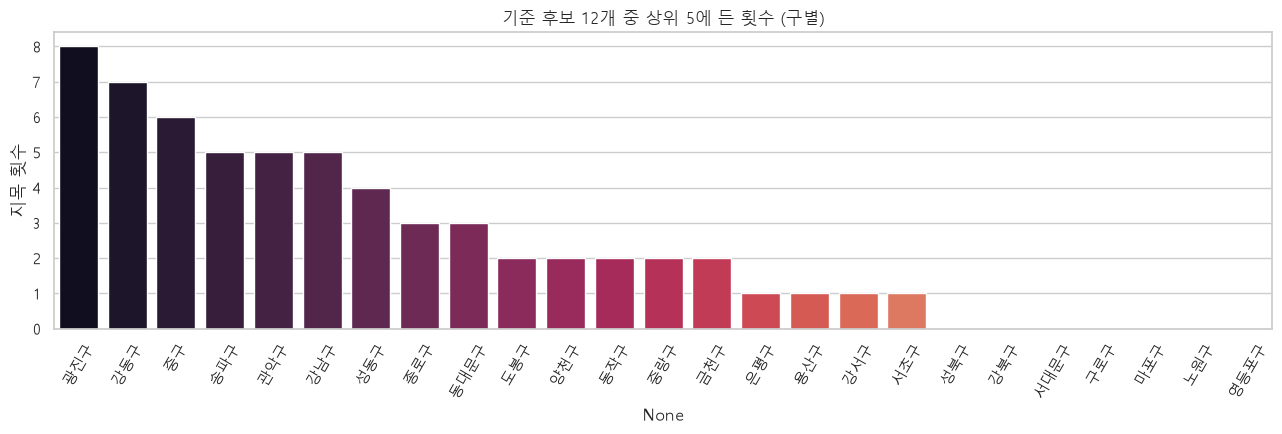

,상위5_지목횟수
광진구,8
강동구,7
중구,6
송파구,5
관악구,5
강남구,5
성동구,4
종로구,3
동대문구,3
도봉구,2


In [19]:
# 몇 개 기준에서 상위5에 들었나 (구별 지목 횟수)
cnt = pd.Series(0, index=GU_ORDER, name="상위5_지목횟수")
for s in TOP5.values():
    for g in s:
        cnt[g] += 1
cnt = cnt.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.barplot(x=cnt.index, y=cnt.values, hue=cnt.index, palette="rocket", legend=False, ax=ax)
ax.set_title(f"기준 후보 {len(TOP5)}개 중 상위 5에 든 횟수 (구별)")
ax.set_ylabel("지목 횟수"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

cnt.to_frame()

## 10. 최종 표 (보고서용)

In [20]:
SHOW = ["자치구", "승차합", "하차합", "정류장수", "노선수", "도착이동인구", "순유입",
        "인구", "종사자수", "정류장당승차", "노선당승차", "인구만명당정류장",
        "도착이동인구만명당정류장", "버스이용률", "가중평균이동시간",
        "출근도착비중(%)", "밤도착비중(%)", "심야도착비중(%)"]
final = df[SHOW].copy()
final["잔차z_도착이동인구"] = resid["잔차z_도착이동인구"].reindex(final["자치구"]).values
final["잔차z_인구"] = resid["잔차z_인구"].reindex(final["자치구"]).values
final["잔차z_종사자수"] = resid["잔차z_종사자수"].reindex(final["자치구"]).values
final.to_csv(PROC / "df_gu_eda_final.csv", index=False, encoding="utf-8-sig")
print("저장:", (PROC / "df_gu_eda_final.csv").resolve())
final.round(3)

저장: C:\study\aix\aix_2\data\processed\df_gu_eda_final.csv


,자치구,승차합,하차합,정류장수,노선수,도착이동인구,순유입,인구,종사자수,정류장당승차,노선당승차,인구만명당정류장,도착이동인구만명당정류장,버스이용률,가중평균이동시간,출근도착비중(%),밤도착비중(%),심야도착비중(%),잔차z_도착이동인구,잔차z_인구,잔차z_종사자수
0,종로구,5468935,5205394,349,106,19809988.63,-52443.07,153684,16494,15670.301,51593.726,22.709,0.176,0.276,16.597,17.779,5.973,2.142,0.516,1.152,0.593
1,중구,3776675,3598932,178,103,20275545.43,-21100.35,131450,40018,21217.275,36666.748,13.541,0.088,0.186,16.634,20.373,6.025,2.763,-0.983,-0.058,-1.619
2,용산구,4189977,4086474,323,67,15247193.24,98792.93,236518,11449,12972.065,62536.970,13.656,0.212,0.275,16.550,13.981,9.928,3.542,-0.179,-0.071,-0.181
3,성동구,2807280,2746738,435,58,18076235.50,-45035.59,291609,15868,6453.517,48401.379,14.917,0.241,0.155,16.371,15.078,9.607,3.468,-1.623,-1.287,-1.407
4,광진구,2749448,2753411,269,41,18715186.44,40063.61,353110,15715,10220.996,67059.707,7.618,0.144,0.147,16.007,11.594,11.660,4.103,-1.729,-1.522,-1.445
5,동대문구,5240565,5115379,306,73,16987577.97,14474.50,352592,15237,17126.029,71788.562,8.679,0.180,0.308,15.923,14.244,10.711,4.118,0.571,0.362,0.469
6,중랑구,3792541,3740923,380,48,14518503.71,8575.91,393600,17700,9980.371,79011.271,9.654,0.262,0.261,16.147,12.013,11.735,4.209,-0.456,-0.859,-0.729
7,성북구,6236424,6231238,602,99,19524264.96,-33823.69,442680,15177,10359.508,62994.182,13.599,0.308,0.319,16.086,12.515,11.627,3.929,1.203,0.835,1.229
8,강북구,4825181,4671783,413,67,13079023.71,-5036.57,300824,12526,11683.247,72017.627,13.729,0.316,0.369,16.218,12.425,11.017,3.889,0.562,0.209,0.260
9,도봉구,3304305,3211421,359,46,11243990.02,-9826.25,318100,14469,9204.192,71832.717,11.286,0.319,0.294,16.039,12.315,10.936,3.757,-0.585,-0.994,-0.974


In [21]:
# 마크다운 표 (report_EDA.md에 붙일 형태)
print(final.round(3).to_markdown(index=False))

| 자치구   |   승차합 |   하차합 |   정류장수 |   노선수 |   도착이동인구 |    순유입 |   인구 |   종사자수 |   정류장당승차 |   노선당승차 |   인구만명당정류장 |   도착이동인구만명당정류장 |   버스이용률 |   가중평균이동시간 |   출근도착비중(%) |   밤도착비중(%) |   심야도착비중(%) |   잔차z_도착이동인구 |   잔차z_인구 |   잔차z_종사자수 |
|:---------|---------:|---------:|-----------:|---------:|---------------:|----------:|-------:|-----------:|---------------:|-------------:|-------------------:|---------------------------:|-------------:|-------------------:|------------------:|----------------:|------------------:|---------------------:|-------------:|-----------------:|
| 종로구   |  5468935 |  5205394 |        349 |      106 |    1.981e+07   | -52443.1  | 153684 |      16494 |       15670.3  |      51593.7 |             22.709 |                      0.176 |        0.276 |             16.597 |            17.779 |           5.973 |             2.142 |                0.516 |        1.152 |            0.593 |
| 중구     |  3776675 |  3598932 |        178 |      103 |    2.02755e+07 | -21100.3  